# 19b · Code search needs identifiers and intent

## The engineering question
Which code-search queries need exact symbols, and which need a semantic description of behavior?

**Learning outcomes:** index function boundaries with file/line provenance; compare lexical, dense, and fused retrieval; keep development/test function families distinct; inspect generic-encoder limitations and source-code trust boundaries.

The corpus consists of eight author-created Python functions. We parse their AST boundaries without importing or executing them. Development queries target collection utilities; held-out queries target I/O and date/retry functions. All functions remain searchable, but test questions do not tune retrieval parameters. Function comments/docstrings are indexed as untrusted source text.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("19b", "B", docker=False)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


,split,query,method,top_function,recall,mrr
0,development,unique_in_order,BM25,unique_in_order,1.0,1.0
1,development,unique_in_order,generic dense,unique_in_order,1.0,1.0
2,development,unique_in_order,RRF60,unique_in_order,1.0,1.0
3,development,remove duplicates without changing order,BM25,unique_in_order,1.0,1.0
4,development,remove duplicates without changing order,generic dense,unique_in_order,1.0,1.0
5,development,remove duplicates without changing order,RRF60,unique_in_order,1.0,1.0
6,development,find_device_by_serial,BM25,find_device_by_serial,1.0,1.0
7,development,find_device_by_serial,generic dense,find_device_by_serial,1.0,1.0
8,development,find_device_by_serial,RRF60,find_device_by_serial,1.0,1.0
9,development,look up a device by its serial number,BM25,find_device_by_serial,1.0,1.0


,id,family,file,line
0,unique_in_order,collections_examples,datasets/code/collections_examples.py,4
1,descending_numbers,collections_examples,datasets/code/collections_examples.py,9
2,word_counts,collections_examples,datasets/code/collections_examples.py,14
3,find_device_by_serial,collections_examples,datasets/code/collections_examples.py,20
4,read_json,io_examples,datasets/code/io_examples.py,4
5,write_json,io_examples,datasets/code/io_examples.py,11
6,parse_iso_date,io_examples,datasets/code/io_examples.py,18
7,exponential_delay,io_examples,datasets/code/io_examples.py,24


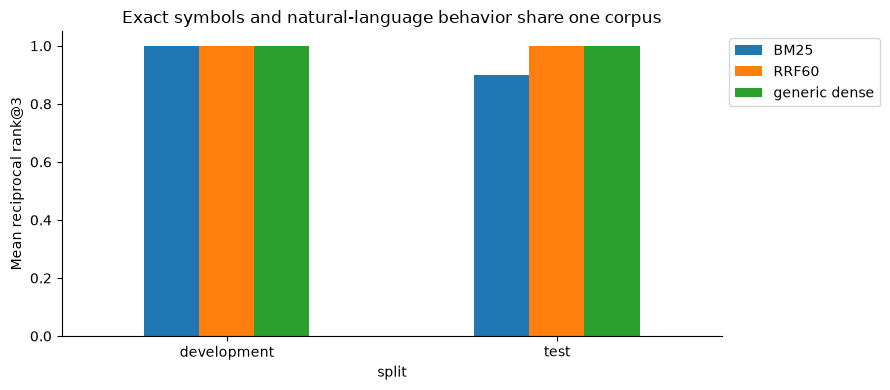

In [2]:
import ast
from vector_masterclass.models import embed
from vector_masterclass.retrieval import LexicalIndex, exact_search, reciprocal_rank_fusion
from vector_masterclass.metrics import ranking_metrics

records = []
for path in sorted((root() / "datasets/code").glob("*.py")):
    source = path.read_text()
    for node in ast.parse(source).body:
        if isinstance(node, ast.FunctionDef):
            records.append(
                {
                    "id": node.name,
                    "family": path.stem,
                    "file": str(path.relative_to(root())),
                    "line": node.lineno,
                    "code": ast.get_source_segment(source, node),
                }
            )
ids = [r["id"] for r in records]
texts = [r["code"] for r in records]
lexical = LexicalIndex(texts, ids)
vectors = embed(texts)
queries = [
    ("development", "unique_in_order", "unique_in_order"),
    ("development", "remove duplicates without changing order", "unique_in_order"),
    ("development", "find_device_by_serial", "find_device_by_serial"),
    ("development", "look up a device by its serial number", "find_device_by_serial"),
    ("test", "read_json", "read_json"),
    ("test", "load an object from a JSON file", "read_json"),
    ("test", "parse_iso_date", "parse_iso_date"),
    ("test", "turn a year month day string into a date", "parse_iso_date"),
    ("test", "calculate a retry delay that doubles but has an upper limit", "exponential_delay"),
]
rows = []
for split, text, gold in queries:
    dense = [id_ for id_, score in exact_search(embed([text], role="query")[0], vectors, ids, k=8)]
    words = [id_ for id_, score in lexical.search(text, k=8)]
    fused = [id_ for id_, score in reciprocal_rank_fusion([dense, words])]
    for method, ranked in [("BM25", words), ("generic dense", dense), ("RRF60", fused)]:
        rows.append(
            {
                "split": split,
                "query": text,
                "method": method,
                "top_function": ranked[0],
                **ranking_metrics(ranked, {gold: 1}, k=3),
            }
        )
results = lesson.table(pd.DataFrame(rows))
display(results[["split", "query", "method", "top_function", "recall", "mrr"]])
display(lesson.table(pd.DataFrame(records)[["id", "family", "file", "line"]], "source-map"))
fig, ax = plt.subplots(figsize=(9, 4))
results.groupby(["split", "method"]).mrr.mean().unstack().plot.bar(ax=ax)
ax.set(
    ylabel="Mean reciprocal rank@3",
    ylim=(0, 1.05),
    title="Exact symbols and natural-language behavior share one corpus",
)
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
Exact symbol queries give a cheap lexical baseline. Natural-language queries can benefit from embeddings, but the generic encoder used here was not selected through a code-retrieval benchmark. Function-level chunks retain signatures/docstrings; a call graph or surrounding module may be needed for behavior spread across functions.

**Exercise:** rename a function while preserving its body, then compare symbol and intent queries on development data. Remove a docstring and inspect the change. Explain why retrieved code must not be automatically executed and why comments can contain prompt injection just like other documents.

Production code search also requires branch/commit identity, generated/vendor-code filtering, repository permissions, secret handling, and evaluation across repositories rather than nearby duplicated functions. This lab's source-family split is a small controlled analogue, not proof of cross-repository generalization.

In [3]:
by_id = {r["id"]: r for r in records}
dev_families = {by_id[gold]["family"] for split, text, gold in queries if split == "development"}
test_families = {by_id[gold]["family"] for split, text, gold in queries if split == "test"}
manifest = lesson.finish(
    {
        "eight_parsed_functions": len(records) == 8,
        "source_family_split": not dev_families & test_families,
        "lexical_baseline_present": "BM25" in set(results.method),
        "source_lines_recorded": all(r["line"] > 0 for r in records),
    },
    observations={
        "encoder": "generic pinned MiniLM; no code-specific performance claim",
        "code_execution": "AST parsing and text embedding only",
        "k": 3,
    },
)

{
  "artifact": "artifacts/20261031T060352Z-3a56d5/19b",
  "checks": {
    "eight_parsed_functions": true,
    "source_family_split": true,
    "lexical_baseline_present": true,
    "source_lines_recorded": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.